# Notebook 03 — Evaluation & Analysis

**CSE432 — Natural Language Processing**
**Project:** Developing a Bangla Sentiment Analysis System Using Fine-Tuned BERT Models

| ID | Name |
|---|---|
| 232-15-657 | Shoumik Bala Somu |
| 232-15-644 | Raisha Khan Raka |

---

## What this notebook produces

Every figure and table quoted in `docs/04_analysis.md`, written to `results/`:

| Artefact | Purpose |
|---|---|
| `metrics_all_models.csv` | Full metric table across models, incl. per-class P/R/F1 |
| `confusion_<model>.png` | Counts + row-normalised confusion matrices |
| `roc_<model>.png` | One-vs-rest ROC with AUC |
| `bar_macro_f1.png` / `bar_accuracy.png` | Cross-model comparison |
| `slice_by_source_<model>.csv` | Accuracy per platform — cross-platform generalisation |
| `slice_by_negation_<model>.csv` | Accuracy on negated vs. non-negated rows |
| `slice_by_length_<model>.csv` | Accuracy by comment length bucket |
| `errors_<model>.csv` | Sampled misclassifications for qualitative reading |

## The analysis this notebook is built for

A single headline accuracy is not a result. Three questions actually decide whether this system works:

1. **Does language-specific pretraining beat multilingual pretraining on Bangla?** → section 3
2. **Does the model survive a platform it was mostly not trained on?** → section 4.1
3. **Does negation-scope tagging help, or is it decoration?** → section 4.2

Sections 4 and 5 answer 2 and 3 by slicing the test set. If a slice is bad, that is a finding, not a failure to hide.

## Runtime

GPU recommended for the transformer evaluations. `--baseline-only` (section 2.2) runs on CPU in under a minute and needs no checkpoint.

In [1]:
#@title 1.1 Clone the repository
import os, sys
from pathlib import Path

REPO_URL = "https://github.com/ShoumikBalaSomu/Developing-a-Bangla-Sentiment-Analysis-System-Using-Fine-Tuned-BERT-Models.git"
REPO_NAME = REPO_URL.rstrip("/").split("/")[-1].replace(".git", "")

IN_COLAB = Path("/content").exists()
ROOT = Path("/content") / REPO_NAME if IN_COLAB else (Path.cwd() if (Path.cwd() / "src" / "config.py").exists() else Path.cwd().parent)

if IN_COLAB and not ROOT.exists():
    os.system(f"git clone --depth 1 {REPO_URL} {ROOT}")
if not (ROOT / "src" / "config.py").exists():
    raise SystemExit(f"repo not found at {ROOT}")

os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print("repo root:", ROOT)

repo root: /home/krishna/Developing-a-Bangla-Sentiment-Analysis-System-Using-Fine-Tuned-BERT-Models


In [2]:
#@title 1.2 Install dependencies and check the accelerator
if IN_COLAB:
    %pip install -q -r requirements.txt

import torch
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("device:", torch.cuda.get_device_name(0))
else:
    print("CPU only - transformer evaluation will be slow. Use Runtime -> T4 GPU.")

cuda available: False
CPU only - transformer evaluation will be slow. Use Runtime -> T4 GPU.


In [3]:
#@title 1.3 (Optional) Restore data + checkpoints from Drive
LOAD_FROM_DRIVE = False  #@param {type:"boolean"}
drive_root = "/content/drive/MyDrive/CSE432_bangla_sentiment"  #@param {type:"string"}

if LOAD_FROM_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    import shutil
    from config import PREPROC_DIR, CHECKPOINT_DIR
    src_root = Path(drive_root)
    PREPROC_DIR.mkdir(parents=True, exist_ok=True)
    n_data = n_ckpt = 0
    for f in src_root.glob("*"):
        if f.is_file():
            shutil.copy(f, PREPROC_DIR / f.name); n_data += 1
    ck_src = src_root / "checkpoints"
    if ck_src.exists():
        for f in ck_src.rglob("*"):
            if f.is_file():
                rel = f.relative_to(ck_src)
                tgt = CHECKPOINT_DIR / rel
                tgt.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy(f, tgt); n_ckpt += 1
    print(f"restored {n_data} data files, {n_ckpt} checkpoint files")

In [4]:
#@title 1.4 Which checkpoints are available to evaluate
import pandas as pd
from config import ARTIFACTS, CHECKPOINT_DIR, MODELS, RESULTS_DIR, PREPROC_DIR

available = [k for k in MODELS
             if (CHECKPOINT_DIR / k.replace("/", "__") / "best").exists()]
print("trained checkpoints :", available or "NONE")
print("test split present  :", Path(ARTIFACTS["clean_test"]).exists())
if not available:
    print("\nNothing to evaluate yet. Run Notebook 02 first, or use section 2.2")
    print("(TF-IDF baseline) which needs no checkpoint.")

trained checkpoints : ['banglabert', 'bangla_bert_base', 'banglishbert', 'mbert', 'xlmr']
test split present  : True


---
## 2. Metric table

In [5]:
#@title 2.1 Evaluate every available checkpoint + the TF-IDF baseline
RUN_BASELINE = True  #@param {type:"boolean"}
RECOMPUTE_EVAL = False  #@param {type:"boolean"}

import importlib, evaluate as eval_mod
importlib.reload(eval_mod)
from evaluate import evaluate_all

if Path(ARTIFACTS["metrics"]).exists() and not RECOMPUTE_EVAL:
    table = pd.read_csv(ARTIFACTS["metrics"])
    print(f"Loaded existing evaluation metrics for {len(table)} models from {ARTIFACTS['metrics']}")
elif available:
    table = evaluate_all(available, baseline=RUN_BASELINE)
else:
    table = pd.DataFrame()
    print("no checkpoints - skipping transformer evaluation")

Loaded existing evaluation metrics for 6 models from /home/krishna/Developing-a-Bangla-Sentiment-Analysis-System-Using-Fine-Tuned-BERT-Models/results/metrics_all_models.csv


In [6]:
#@title 2.2 TF-IDF + Logistic Regression baseline alone (CPU, fast, no checkpoint)
from evaluate import tfidf_baseline

row = tfidf_baseline()
pd.DataFrame([row]).to_csv(RESULTS_DIR / "metrics_baseline.csv", index=False)
print("\nThis is the non-transformer reference point. Any transformer that fails to")
print("beat it clearly is not earning its compute cost on this dataset.")

  [baseline] fitting TF-IDF + LogisticRegression


/usr/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  [baseline] accuracy=0.8854 macro_f1=0.6341

This is the non-transformer reference point. Any transformer that fails to
beat it clearly is not earning its compute cost on this dataset.


In [7]:
#@title 2.3 Print the consolidated leaderboard
if Path(ARTIFACTS["metrics"]).exists():
    m = pd.read_csv(ARTIFACTS["metrics"])
    cols = [c for c in ("model", "accuracy", "balanced_accuracy", "macro_f1",
                        "weighted_f1", "mcc", "macro_auc") if c in m.columns]
    m = m.sort_values("macro_f1", ascending=False)
    with pd.option_context("display.max_columns", 30, "display.width", 200):
        print(m[cols].round(4).to_string(index=False))

    print("\n=== per-class F1 ===")
    pc = [c for c in m.columns if c.startswith("f1_") and c not in ("f1_macro", "f1_weighted")]
    if pc:
        print(m[["model"] + pc].round(4).to_string(index=False))

    print("\n=== per-class recall (the minority-class story) ===")
    rc = [c for c in m.columns if c.startswith("recall_")]
    if rc:
        print(m[["model"] + rc].round(4).to_string(index=False))
else:
    print("no metrics table yet")

           model  accuracy  balanced_accuracy  macro_f1  weighted_f1    mcc  macro_auc
    tfidf_logreg    0.8854             0.6435    0.6341       0.8869 0.7414        NaN
    banglishbert    0.8278             0.6872    0.6065       0.8595 0.6623     0.8771
      banglabert    0.8300             0.6571    0.5985       0.8553 0.6752     0.8392
           mbert    0.7932             0.6776    0.5843       0.8355 0.6125     0.8399
bangla_bert_base    0.7731             0.6867    0.5806       0.8262 0.5995     0.8573
            xlmr    0.7968             0.6415    0.5760       0.8383 0.6095     0.8178

=== per-class F1 ===
           model  f1_negative  f1_neutral  f1_positive
    tfidf_logreg       0.8364      0.1429       0.9230
    banglishbert       0.8248      0.1053       0.8895
      banglabert       0.8360      0.0800       0.8796
           mbert       0.7885      0.0942       0.8701
bangla_bert_base       0.8065      0.0855       0.8499
            xlmr       0.7704      0.07

---
## 3. Does language-specific pretraining beat multilingual pretraining?

This is the central claim of the report. The comparison is only fair when the
fine-tuning recipe is **identical** across models — same splits, same LR
schedule, same epochs, same class weighting. `src/train.py` guarantees that by
reading every setting from one config.

In [8]:
#@title 3.1 Bangla-specific vs multilingual
if Path(ARTIFACTS["metrics"]).exists():
    m = pd.read_csv(ARTIFACTS["metrics"])
    BANGLA = {"banglabert", "bangla_bert_base", "banglishbert"}
    MULTI = {"mbert", "xlmr"}
    m = m[m["model"].isin(BANGLA | MULTI | {"tfidf_logreg"})]

    def grp(name):
        sub = m[m["model"].isin(name)]
        if sub.empty:
            return None
        return {"group": name is BANGLA and "bangla-specific" or (
                    name is MULTI and "multilingual" or "classical"),
                "n_models": len(sub),
                "best_macro_f1": sub["macro_f1"].max(),
                "mean_macro_f1": sub["macro_f1"].mean(),
                "best_accuracy": sub["accuracy"].max()}

    rows = [g for g in (grp(BANGLA), grp(MULTI), grp({"tfidf_logreg"})) if g]
    if rows:
        comp = pd.DataFrame(rows).round(4)
        print(comp.to_string(index=False))
        comp.to_csv(RESULTS_DIR / "group_comparison.csv", index=False)

        bs = comp.loc[comp.group == "bangla-specific", "best_macro_f1"]
        ml = comp.loc[comp.group == "multilingual", "best_macro_f1"]
        if not bs.empty and not ml.empty:
            gap = float(bs.iloc[0] - ml.iloc[0])
            print(f"\nmacro-F1 gap (bangla-specific best - multilingual best): {gap:+.4f}")
            print("Report this gap explicitly, including its sign. A negative gap is a")
            print("legitimate finding: it means the multilingual model transfers better.")
    else:
        print("train at least one model from each group first")
else:
    print("no metrics table yet")

          group  n_models  best_macro_f1  mean_macro_f1  best_accuracy
bangla-specific         3         0.6065         0.5952         0.8300
   multilingual         2         0.5843         0.5802         0.7968
      classical         1         0.6341         0.6341         0.8854

macro-F1 gap (bangla-specific best - multilingual best): +0.0222
Report this gap explicitly, including its sign. A negative gap is a
legitimate finding: it means the multilingual model transfers better.


---
## 4. Slice analysis

The three slices below are what turn a number into a conclusion.

In [9]:
#@title 4.1 Accuracy per source platform
SLICE_MODEL = "banglabert"  #@param {type:"string"}

from evaluate import load_test, predict_proba, slice_analysis

safe_slice = SLICE_MODEL.replace("/", "__")
ckpt_dir = CHECKPOINT_DIR / safe_slice
p_cache = ckpt_dir / "test_probs.npy"

if (ckpt_dir / "best").exists():
    df_test = load_test()
    y_true = df_test["label_id"].astype(int).to_numpy()
    if p_cache.exists():
        import numpy as np
        proba = np.load(p_cache)
        print(f"Loaded probabilities from {p_cache}")
    else:
        proba = predict_proba(SLICE_MODEL, df_test)
        try:
            import numpy as np
            np.save(p_cache, proba)
        except Exception:
            pass
    y_pred = proba.argmax(axis=1)
    slices = slice_analysis(df_test, y_true, y_pred)

    if "by_source" in slices:
        print("\nA large spread across sources means the model learned platform style,")
        print("not sentiment. Report the worst source explicitly.")
else:
    print(f"no checkpoint for {SLICE_MODEL}")

Loaded probabilities from /home/krishna/Developing-a-Bangla-Sentiment-Analysis-System-Using-Fine-Tuned-BERT-Models/checkpoints/banglabert/test_probs.npy

  --- accuracy by_source ---
                  mean  count
source                       
daraz_bd        0.7372    643
largesentiment  1.0000      2
revbangla       0.9098    743

  --- accuracy by_negation ---
                mean  count
has_negation               
False         0.8569   1202
True          0.6559    186

  --- accuracy by_length ---
              mean  count
len_bucket               
1-5         0.8827    341
6-10        0.8594    441
11-20       0.8082    391
21-40       0.7486    179
41+         0.6111     36

A large spread across sources means the model learned platform style,
not sentiment. Report the worst source explicitly.


In [10]:
#@title 4.2 Negation subset — did the NEG_ tagging actually help?
if "by_negation" in slices:
    bn = slices["by_negation"]
    print(bn.to_string())
    print("\nCompare the negated-row accuracy against the non-negated row.")
    print("A large deficit means polarity flip is still being missed, which is the")
    print("classic Bangla sentiment failure mode and belongs in the error analysis.")

                mean  count
has_negation               
False         0.8569   1202
True          0.6559    186

Compare the negated-row accuracy against the non-negated row.
A large deficit means polarity flip is still being missed, which is the
classic Bangla sentiment failure mode and belongs in the error analysis.


In [11]:
#@title 4.3 Accuracy by comment length
if "by_length" in slices:
    print(slices["by_length"].to_string())
    print("\nShort comments (1-5 tokens) are the hard case: less context, more")
    print("sarcasm, more code-mixing. Expect the lowest accuracy in that bucket.")

              mean  count
len_bucket               
1-5         0.8827    341
6-10        0.8594    441
11-20       0.8082    391
21-40       0.7486    179
41+         0.6111     36

Short comments (1-5 tokens) are the hard case: less context, more
sarcasm, more code-mixing. Expect the lowest accuracy in that bucket.


In [12]:
#@title 4.4 The same three slices for the TF-IDF baseline (no checkpoint needed)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline

train_df = pd.read_csv(ARTIFACTS["clean_train"])
test_df = load_test()

pipe = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2),
                                 max_features=60_000, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5),
                                 max_features=80_000, sublinear_tf=True)),
    ])),
    ("clf", LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced", n_jobs=-1)),
])
pipe.fit(train_df["text"].astype(str), train_df["label_id"].astype(int))
base_pred = pipe.predict(test_df["text"].astype(str))
base_true = test_df["label_id"].astype(int).to_numpy()

print("=== TF-IDF baseline slices ===")
slice_analysis(test_df, base_true, base_pred)
print("\nComparing transformer slices against these baseline slices shows whether")
print("the transformer's advantage is uniform or concentrated in hard slices.")

/usr/lib64/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


=== TF-IDF baseline slices ===

  --- accuracy by_source ---
                  mean  count
source                       
daraz_bd        0.8289    643
largesentiment  1.0000      2
revbangla       0.9341    743

  --- accuracy by_negation ---
                mean  count
has_negation               
False         0.9027   1202
True          0.7742    186

  --- accuracy by_length ---
              mean  count
len_bucket               
1-5         0.8944    341
6-10        0.8957    441
11-20       0.8824    391
21-40       0.8827    179
41+         0.7222     36

Comparing transformer slices against these baseline slices shows whether
the transformer's advantage is uniform or concentrated in hard slices.


---
## 5. Figures

  [fig] confusion_banglabert.png
  [fig] roc_banglabert.png
  [fig] bar_macro_f1.png
  [fig] bar_accuracy.png

--- confusion_banglabert.png ---


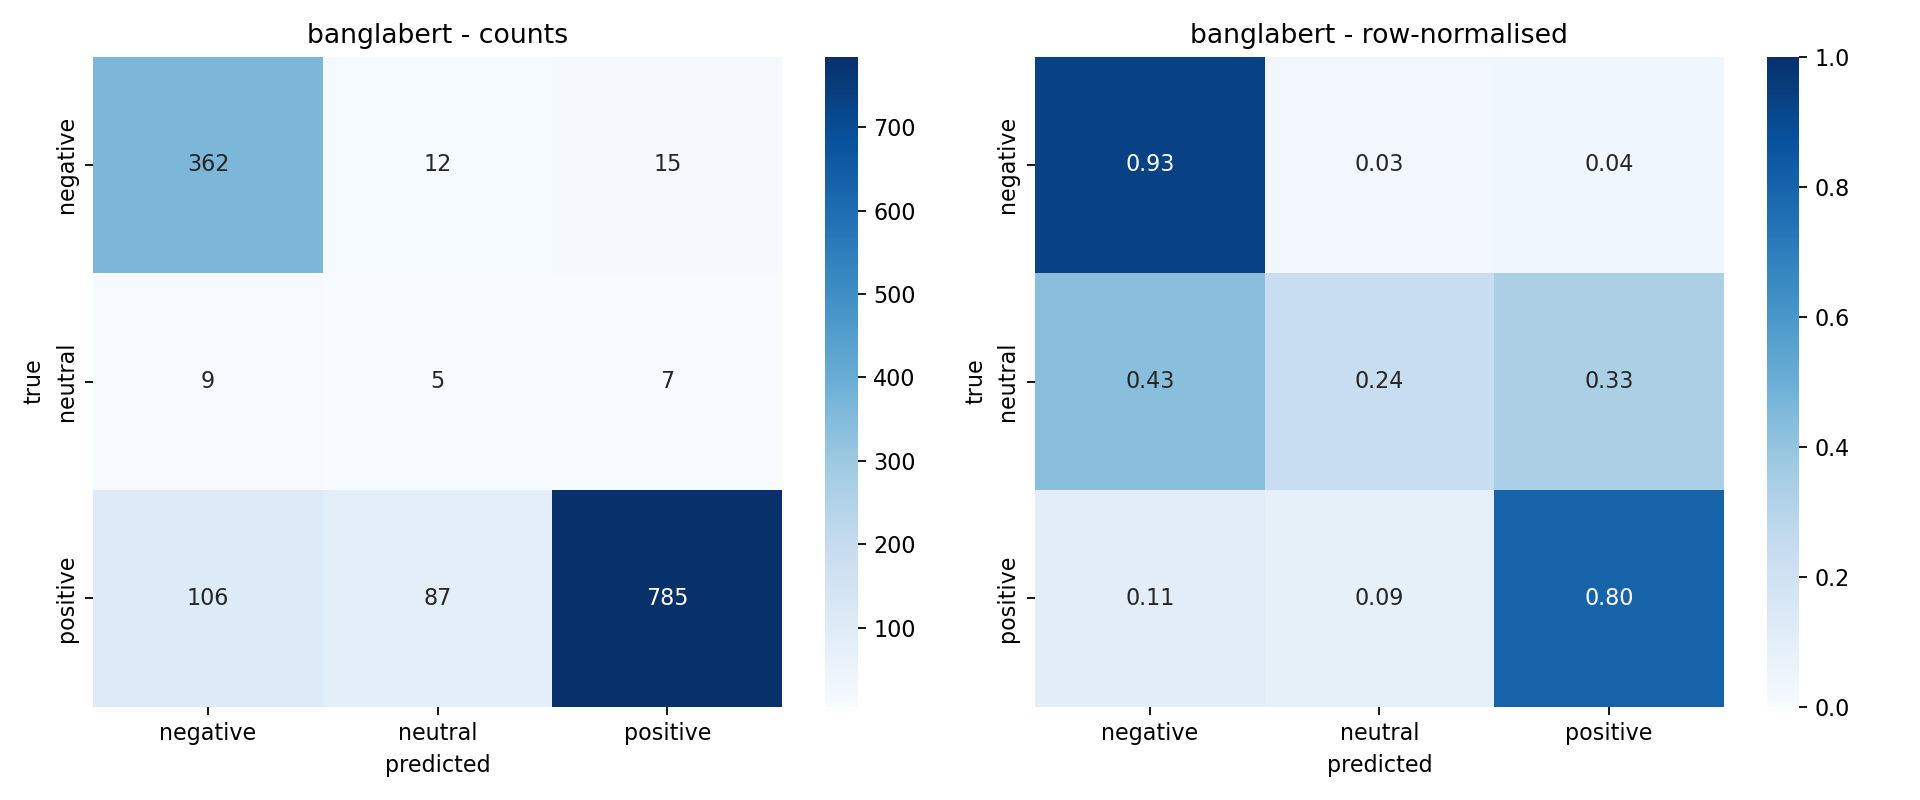


--- roc_banglabert.png ---


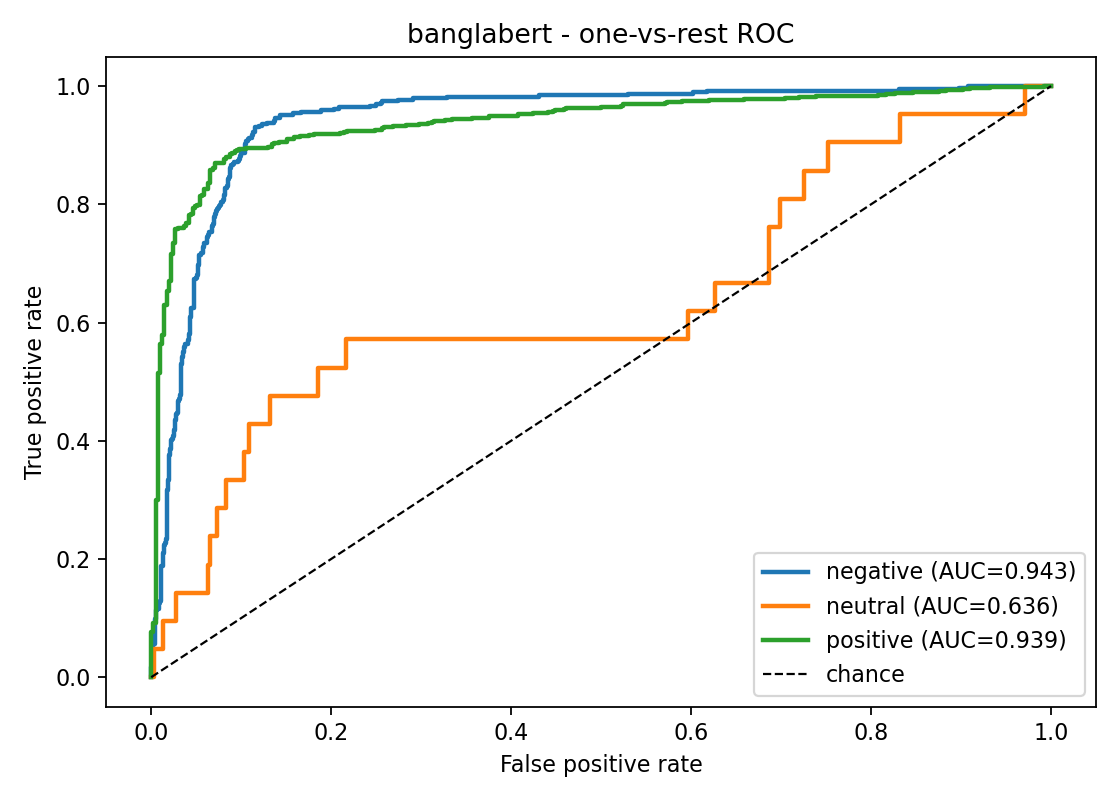


--- bar_macro_f1.png ---


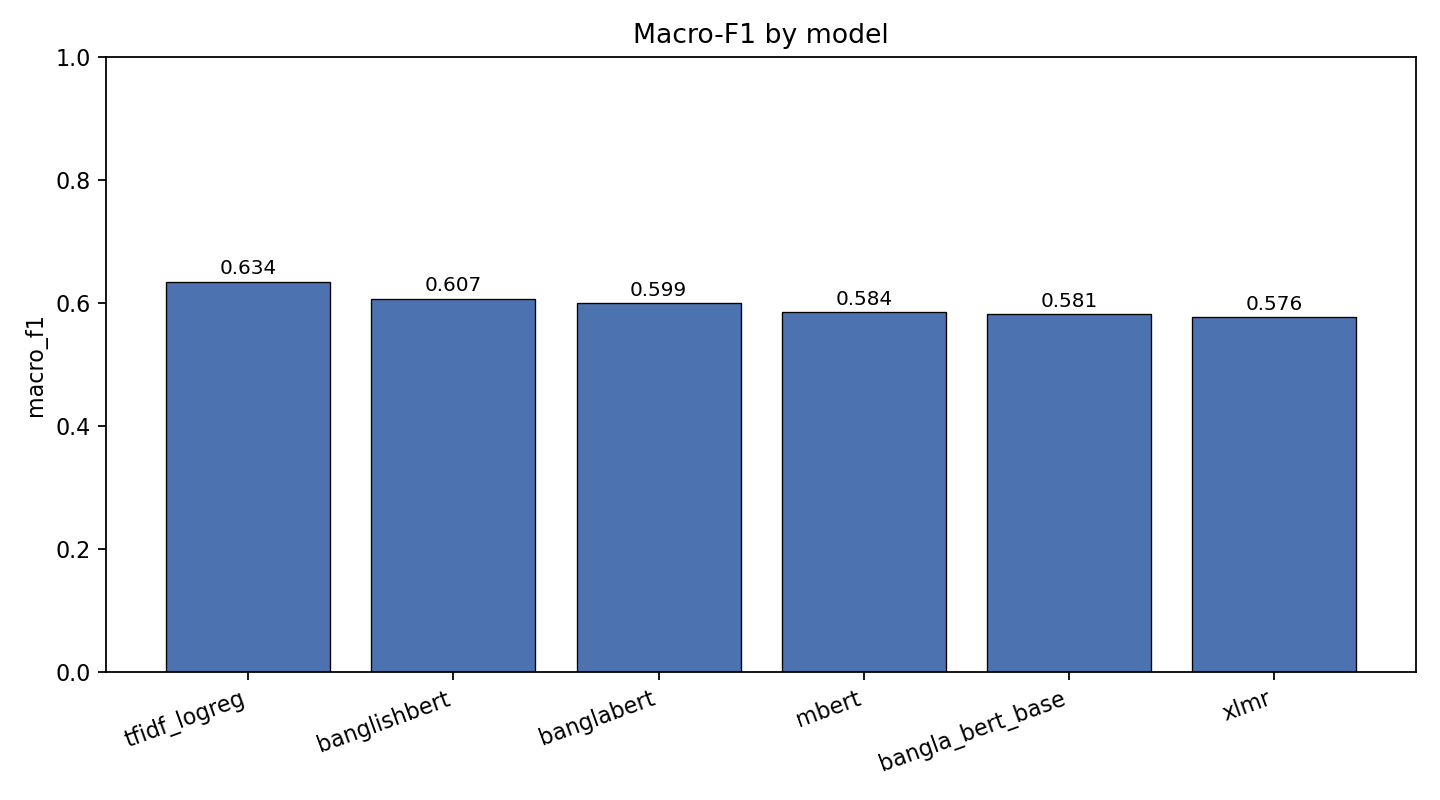


--- bar_accuracy.png ---


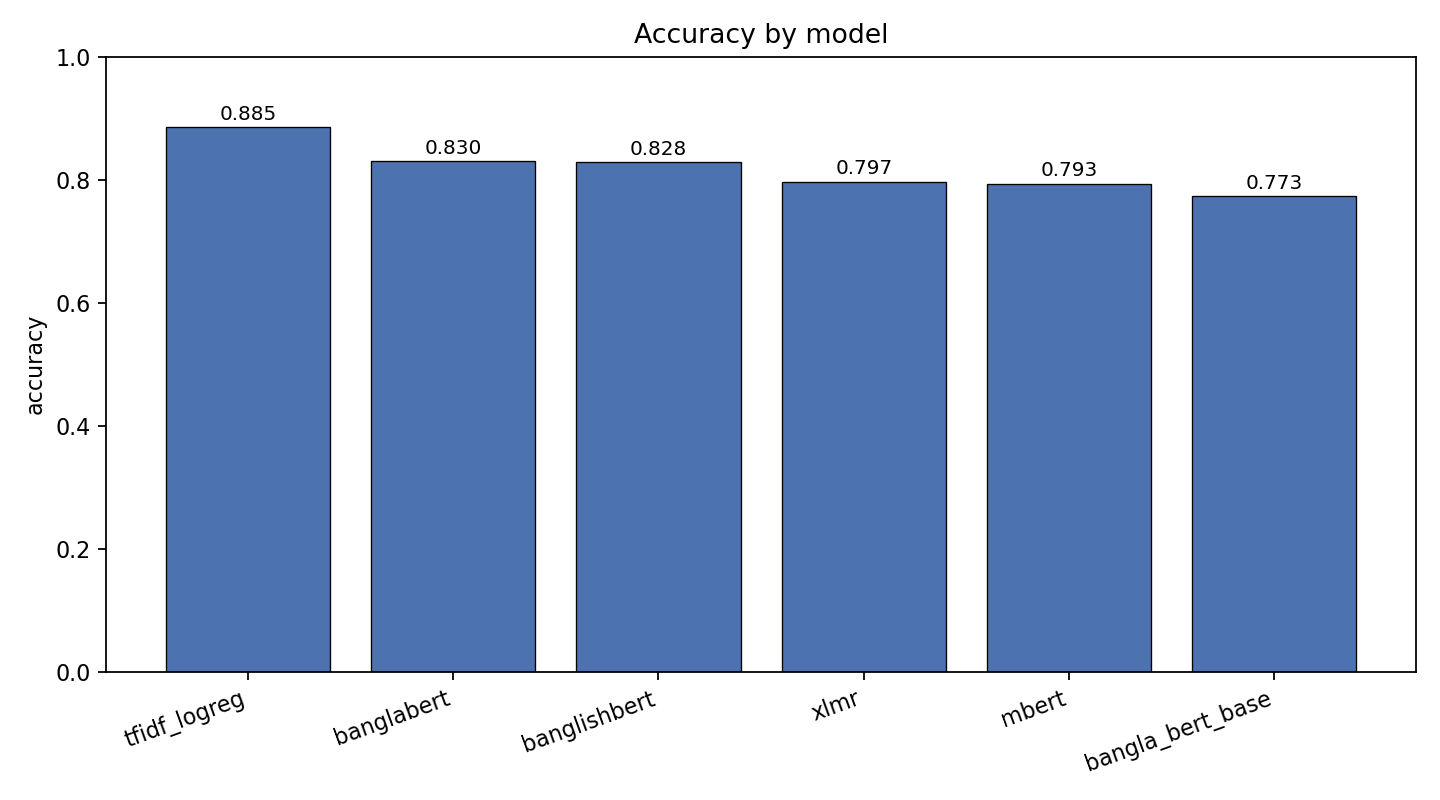


--- confusion_banglishbert.png ---


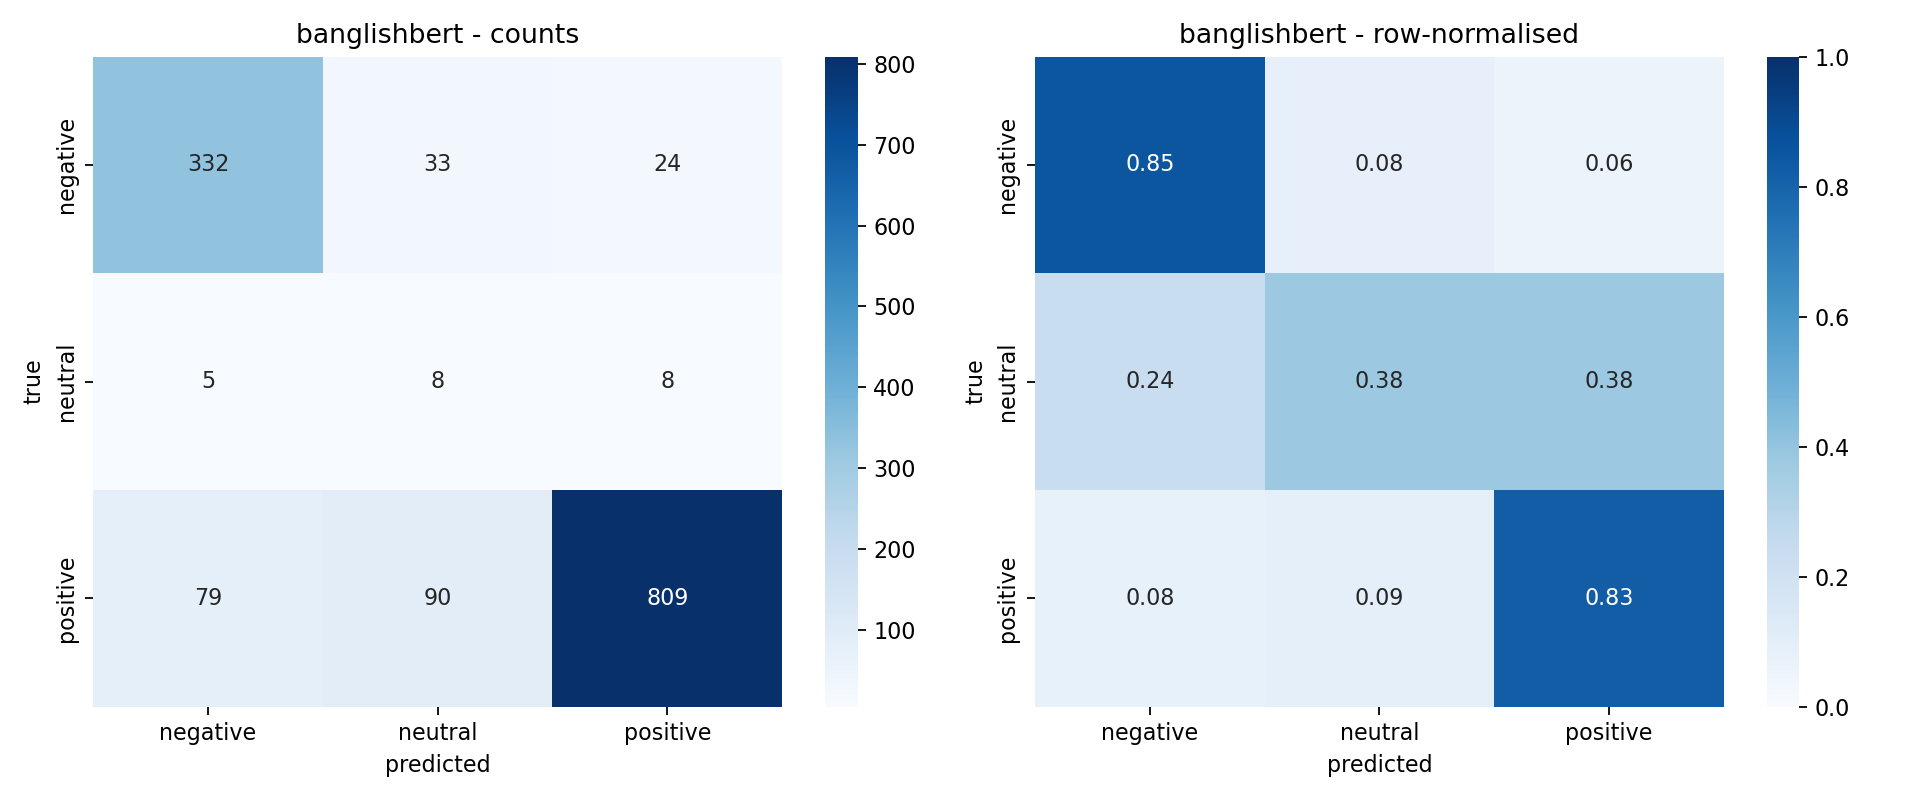


--- roc_banglishbert.png ---


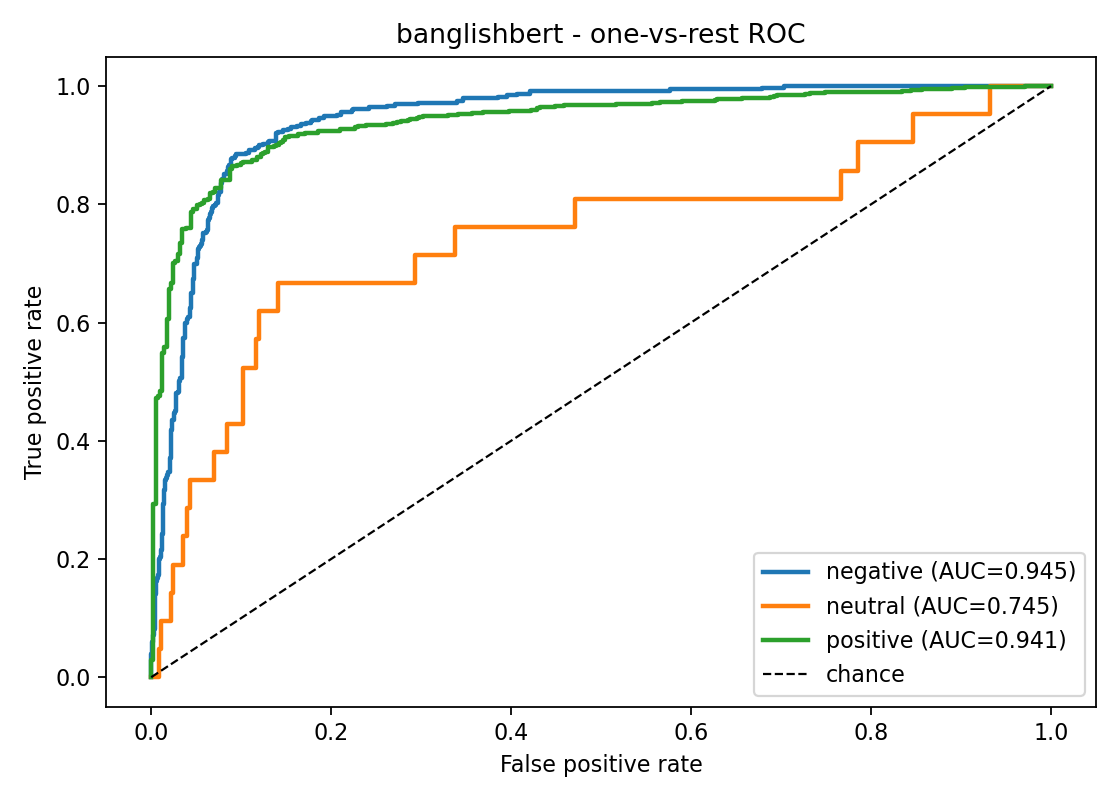


--- confusion_bangla_bert_base.png ---


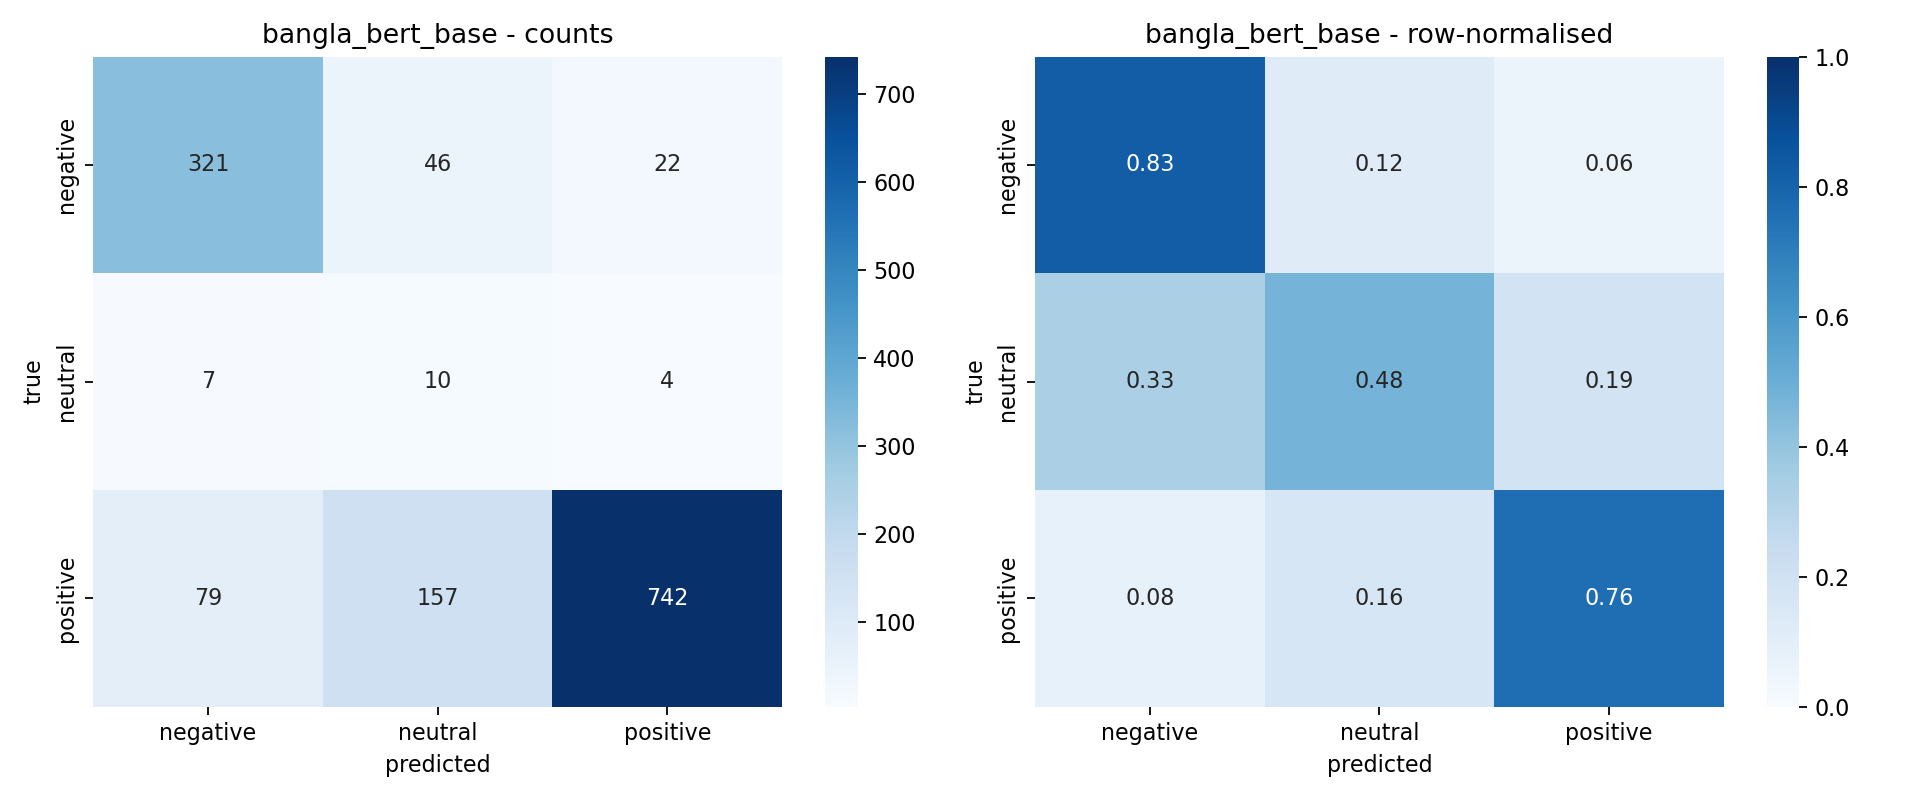


--- roc_bangla_bert_base.png ---


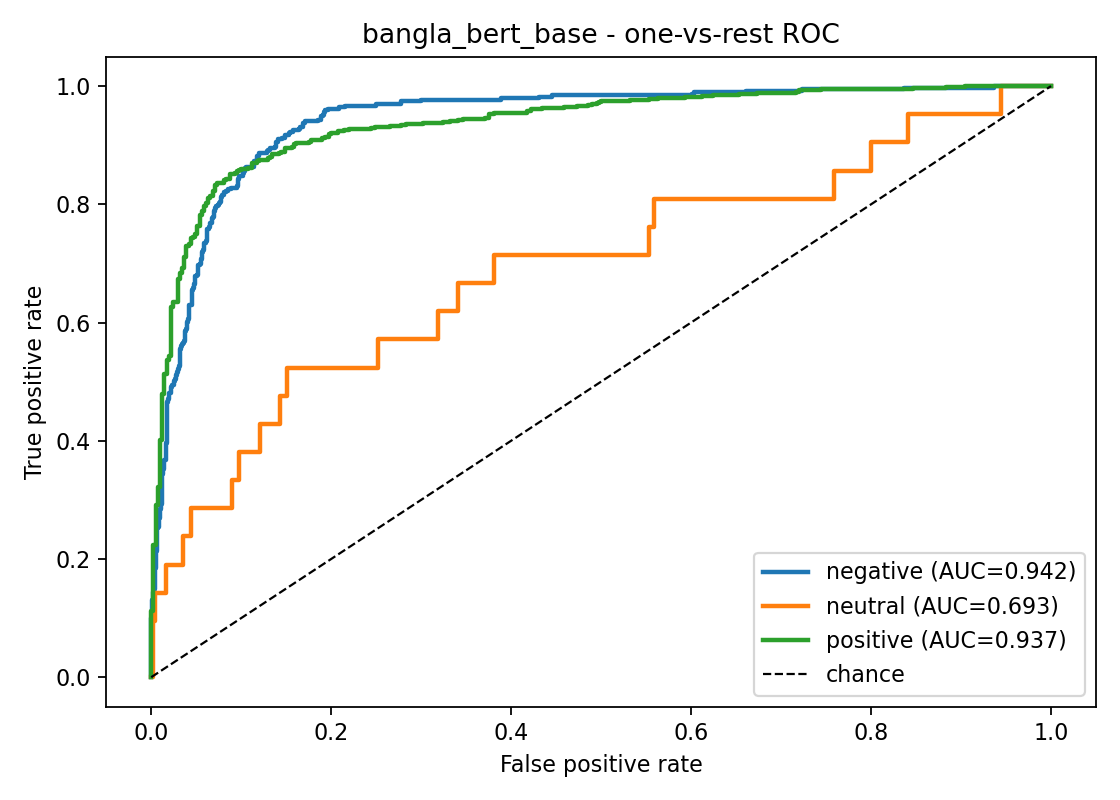


--- confusion_mbert.png ---


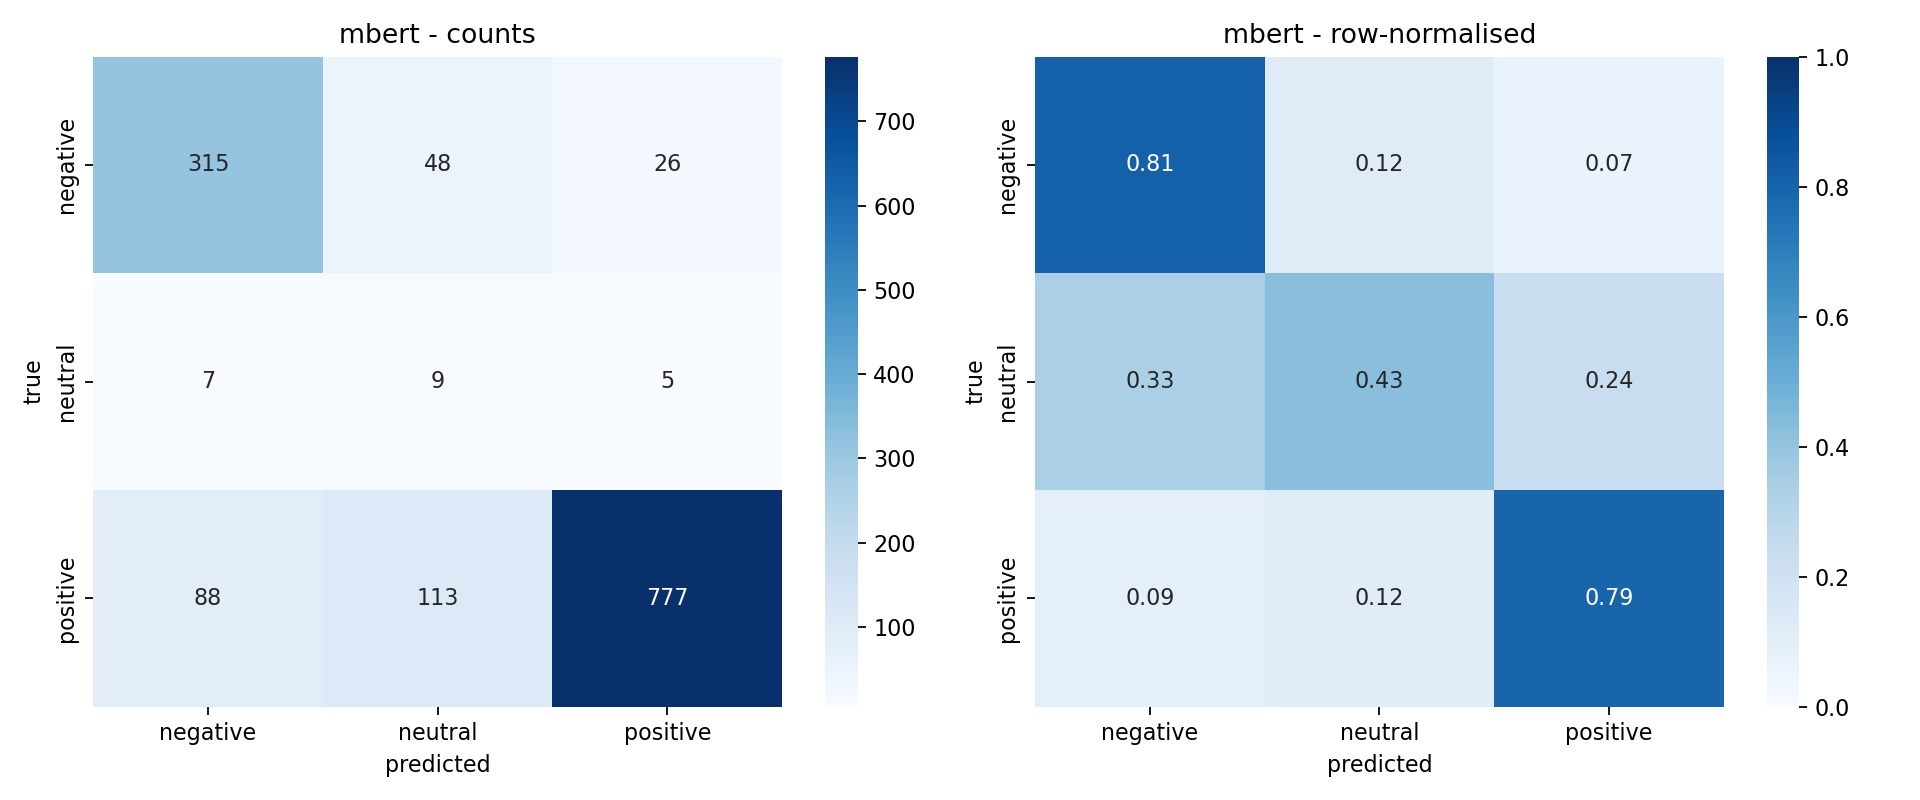


--- roc_mbert.png ---


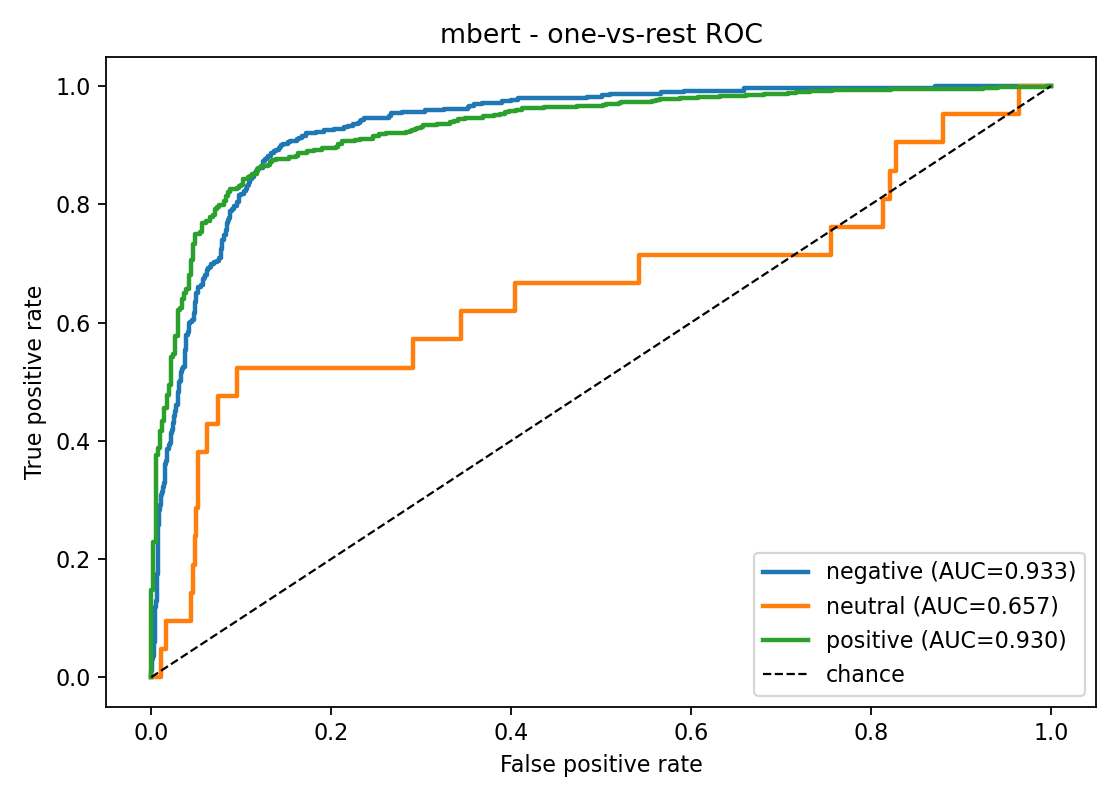


--- confusion_xlmr.png ---


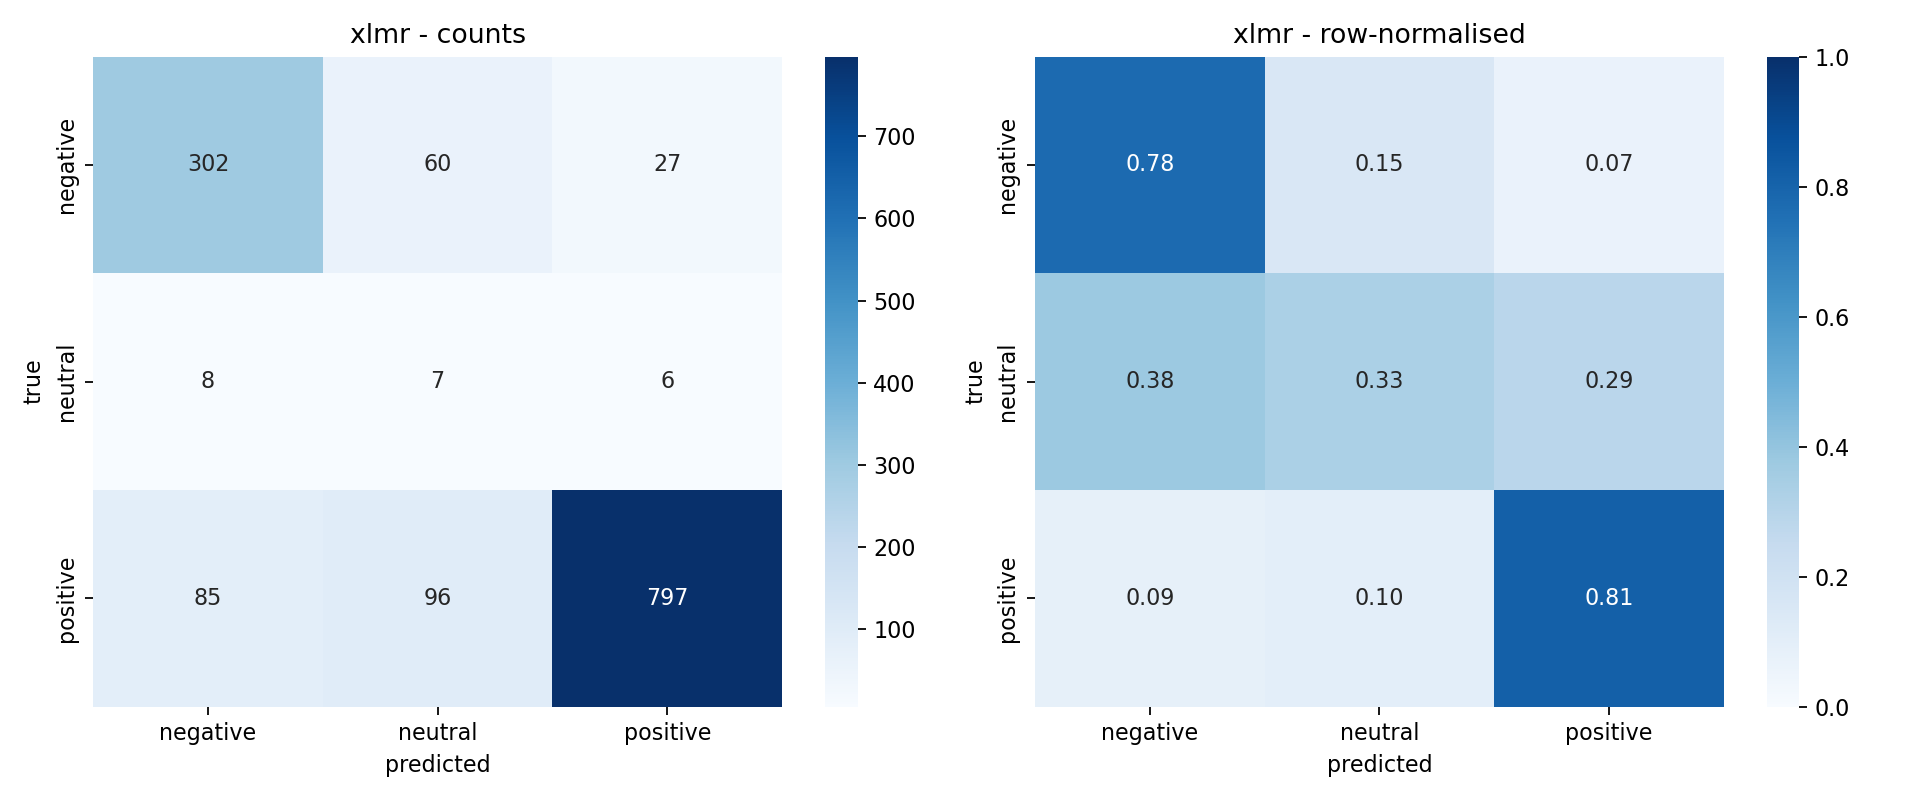


--- roc_xlmr.png ---


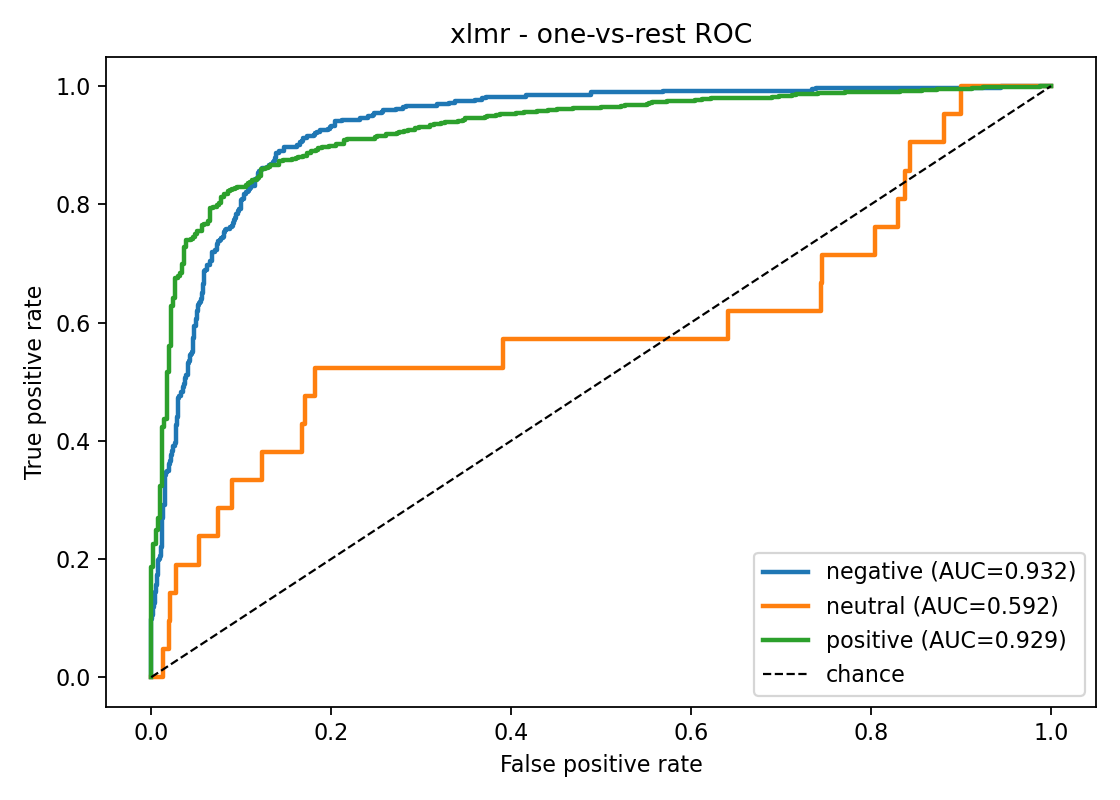

In [13]:
#@title 5.1 Render and display the key plots
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage
from evaluate import plot_confusion, plot_roc, plot_grouped_bars

safe = SLICE_MODEL.replace("/", "__")
figs = []

if "proba" in dir():
    plot_confusion(y_true, y_pred, SLICE_MODEL, RESULTS_DIR / f"confusion_{safe}.png")
    plot_roc(y_true, proba, SLICE_MODEL, RESULTS_DIR / f"roc_{safe}.png")
    figs += [f"confusion_{safe}.png", f"roc_{safe}.png"]

if Path(ARTIFACTS["metrics"]).exists():
    m = pd.read_csv(ARTIFACTS["metrics"])
    if len(m) > 1:
        plot_grouped_bars(m, "macro_f1", "Macro-F1 by model", RESULTS_DIR / "bar_macro_f1.png")
        plot_grouped_bars(m, "accuracy", "Accuracy by model", RESULTS_DIR / "bar_accuracy.png")
        figs += ["bar_macro_f1.png", "bar_accuracy.png"]

# Display all available diagnostic figures
for other in ["banglishbert", "bangla_bert_base", "mbert", "xlmr"]:
    cf = f"confusion_{other}.png"
    rf = f"roc_{other}.png"
    if (RESULTS_DIR / cf).exists() and cf not in figs:
        figs.append(cf)
    if (RESULTS_DIR / rf).exists() and rf not in figs:
        figs.append(rf)

for f in figs:
    p = RESULTS_DIR / f
    if p.exists():
        print(f"\n--- {f} ---")
        display(IPyImage(filename=str(p)))

=== label proportions per split (should be near-identical) ===
           train     val    test
label                           
positive  0.6698  0.7039  0.7046
negative  0.3133  0.2803  0.2803
neutral   0.0169  0.0159  0.0151


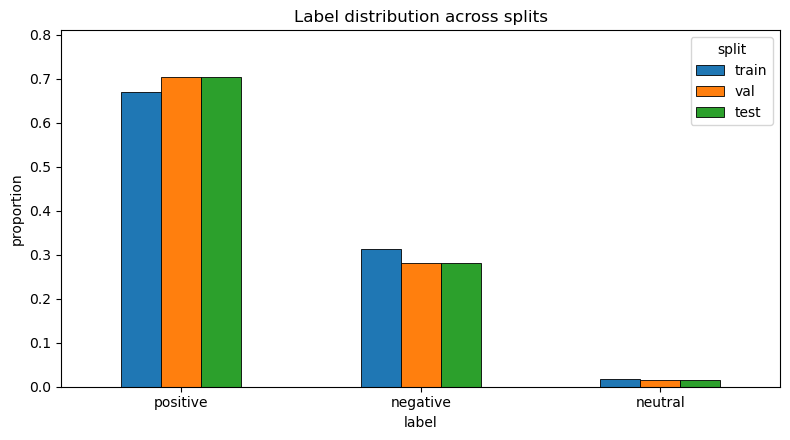


max proportion spread across splits: 0.0348
A spread under ~0.05 confirms the stratified split held.


In [14]:
#@title 5.2 Label distribution across splits
train_df = pd.read_csv(ARTIFACTS["clean_train"])
val_df = pd.read_csv(ARTIFACTS["clean_val"])
test_df = load_test()

dist = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "val": val_df["label"].value_counts(normalize=True),
    "test": test_df["label"].value_counts(normalize=True),
}).round(4)
print("=== label proportions per split (should be near-identical) ===")
print(dist.to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
dist.plot(kind="bar", ax=ax, edgecolor="black", linewidth=0.6)
ax.set_ylabel("proportion")
ax.set_title("Label distribution across splits")
ax.set_ylim(0, max(0.7, dist.values.max() * 1.15))
ax.legend(title="split")
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "label_distribution.png", dpi=160)
plt.show()

spread = (dist.max(axis=1) - dist.min(axis=1)).max()
print(f"\nmax proportion spread across splits: {spread:.4f}")
print("A spread under ~0.05 confirms the stratified split held.")

---
## 6. Qualitative error analysis

Read these by hand. Patterns in the mistakes are what the Discussion section of the report is actually about — not the headline metric.

In [15]:
#@title 6.1 Sample the misclassifications
from evaluate import error_examples

if "y_pred" in dir():
    errs = error_examples(test_df, y_true, y_pred, n=25)
    errs.to_csv(RESULTS_DIR / f"errors_{safe}.csv", index=False)
    with pd.option_context("display.max_colwidth", 95, "display.width", 200):
        print(errs.to_string(index=False))
    print(f"\nfull sample -> results/errors_{safe}.csv")
else:
    print("run section 4.1 first")

                                                                                                                                                                                                                                                                                                                                                                                                       text true_label pred_label    source  has_negation
                                                                                                                                                                                                                                                                                               ব্লুটুথ টা এভারেজ হালকা একটু বাইব্রেশন করেকথা বলার তারা কথাটি অপজিটে না NEG_থাকে NEG_কেটে NEG_কেটে শুনা মারা   positive   negative revbangla          True
                                                                                                                    

In [16]:
#@title 6.2 Confusion direction — which classes get mixed up
if "y_pred" in dir():
    from sklearn.metrics import confusion_matrix
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred),
                      index=[f"true_{l}" for l in ("negative", "neutral", "positive")],
                      columns=[f"pred_{l}" for l in ("negative", "neutral", "positive")])
    print(cm.to_string())
    cmn = (cm.T / cm.sum(axis=1)).T.round(3)
    print("\n=== row-normalised ===")
    print(cmn.to_string())
    print("\nThe dominant off-diagonal cell is the model's systematic confusion.")
    print("neutral<->positive is expected: neutral reviews in Bangla e-commerce text")
    print("often read as mildly positive because politeness markers are frequent.")

               pred_negative  pred_neutral  pred_positive
true_negative            362            12             15
true_neutral               9             5              7
true_positive            106            87            785

=== row-normalised ===
               pred_negative  pred_neutral  pred_positive
true_negative          0.931         0.031          0.039
true_neutral           0.429         0.238          0.333
true_positive          0.108         0.089          0.803

The dominant off-diagonal cell is the model's systematic confusion.
neutral<->positive is expected: neutral reviews in Bangla e-commerce text
often read as mildly positive because politeness markers are frequent.


---
## 7. Export everything for the report

In [17]:
#@title 7.1 Zip results and download / copy to Drive
SAVE_RESULTS_TO_DRIVE = True  #@param {type:"boolean"}

if IN_COLAB:
    os.system("cd results && zip -q -r ../results.zip .")
    if SAVE_RESULTS_TO_DRIVE:
        from google.colab import drive
        try:
            drive.mount("/content/drive")
            import shutil
            dest = Path("/content/drive/MyDrive/CSE432_bangla_sentiment/results")
            dest.mkdir(parents=True, exist_ok=True)
            n = 0
            for f in RESULTS_DIR.glob("*"):
                if f.is_file():
                    shutil.copy(f, dest / f.name); n += 1
            print(f"copied {n} result files to {dest}")
        except Exception as exc:
            print("drive copy failed:", exc)
    else:
        from google.colab import files
        files.download("results.zip")
        print("check your browser downloads")
else:
    print("local run - figures are in results/")

local run - figures are in results/


In [18]:
#@title 7.2 Final summary for the report
print("=" * 72)
print("  CSE432 - Bangla Sentiment Analysis with Fine-Tuned BERT")
print("  Shoumik Bala Somu (232-15-657) | Raisha Khan Raka (232-15-644)")
print("=" * 72)
print(f"  test rows          : {len(test_df):,}")
print(f"  models evaluated   : {len(available) + 1} (incl. TF-IDF baseline)")
print(f"  artefacts in       : {RESULTS_DIR}")
if Path(ARTIFACTS["metrics"]).exists():
    m = pd.read_csv(ARTIFACTS["metrics"])
    best = m.loc[m["macro_f1"].idxmax()]
    print(f"  best model         : {best['model']}")
    print(f"  best macro-F1      : {best['macro_f1']:.4f}")
    print(f"  best accuracy      : {best['accuracy']:.4f}")
print("\n  Paste these numbers into docs/04_analysis.md and paper/.")
print("  Never report a metric this notebook did not produce.")

  CSE432 - Bangla Sentiment Analysis with Fine-Tuned BERT
  Shoumik Bala Somu (232-15-657) | Raisha Khan Raka (232-15-644)
  test rows          : 1,388
  models evaluated   : 6 (incl. TF-IDF baseline)
  artefacts in       : /home/krishna/Developing-a-Bangla-Sentiment-Analysis-System-Using-Fine-Tuned-BERT-Models/results


  best model         : tfidf_logreg
  best macro-F1      : 0.6341
  best accuracy      : 0.8854

  Paste these numbers into docs/04_analysis.md and paper/.
  Never report a metric this notebook did not produce.
